In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

DATA_PATH = Path("../data/processed/all_transactions.csv")

transactions = pd.read_csv(DATA_PATH)
transactions["timestamp"] = pd.to_datetime(
    transactions["timestamp"]
)

transactions = transactions.sort_values(
    "timestamp"
).reset_index(drop=True)

print("Dataset shape:", transactions.shape)
print("Date range:")
print(transactions["timestamp"].min())
print(transactions["timestamp"].max())


Dataset shape: (99975, 12)
Date range:
2026-01-01 00:00:34.132897690
2026-01-30 23:59:43.756698067


In [2]:

MODEL_PATH = Path("../data/processed/model_dataset.csv")

model_data = pd.read_csv(MODEL_PATH)

# Zaman bilgisini orijinal işlem verisinden ekle
model_data["timestamp"] = transactions["timestamp"].values

print("Model dataset:", model_data.shape)
display(model_data.head())


Model dataset: (99975, 20)


,transaction_id,timestamp,amount,amount_log,hour,day_of_week,is_weekend,transaction_type_code,tx_count_1h,tx_count_24h,amount_sum_1h,amount_sum_24h,previous_avg_amount,previous_std_amount,has_transaction_history,amount_vs_avg,amount_zscore,sender_prior_tx_count,receiver_prior_tx_count,is_fraud
0,TXN_0000001,2026-01-01 00:00:34.132897690,226.47,5.427018,0,3,0,1,NaN,NaN,NaN,NaN,NaN,NaN,0,0.0,0.0,0,0,0
1,TXN_0000002,2026-01-01 00:00:34.427735075,381.23,5.946023,0,3,0,2,NaN,NaN,NaN,NaN,NaN,NaN,0,0.0,0.0,0,0,0
2,TXN_0000003,2026-01-01 00:00:49.868826972,36.73,3.630456,0,3,0,3,NaN,NaN,NaN,NaN,NaN,NaN,0,0.0,0.0,0,0,0
3,TXN_0000004,2026-01-01 00:01:11.188848846,20.02,3.045474,0,3,0,1,NaN,NaN,NaN,NaN,NaN,NaN,0,0.0,0.0,0,0,0
4,TXN_0000005,2026-01-01 00:02:02.367877342,49.03,3.912623,0,3,0,3,NaN,NaN,NaN,NaN,NaN,NaN,0,0.0,0.0,0,0,0


In [3]:

split_date = model_data["timestamp"].quantile(0.80)

train_data = model_data[
    model_data["timestamp"] < split_date
].copy()

test_data = model_data[
    model_data["timestamp"] >= split_date
].copy()

print("Split date:", split_date)

print("Training shape:", train_data.shape)
print("Testing shape:", test_data.shape)

print("\nTraining date range:")
print(train_data["timestamp"].min())
print(train_data["timestamp"].max())

print("\nTesting date range:")
print(test_data["timestamp"].min())
print(test_data["timestamp"].max())


Split date: 2026-01-24 23:21:34.873372672
Training shape: (79980, 20)
Testing shape: (19995, 20)

Training date range:
2026-01-01 00:00:34.132897690
2026-01-24 23:21:29.093211014

Testing date range:
2026-01-24 23:21:57.994019054
2026-01-30 23:59:43.756698067


In [4]:

print("TRAINING TARGET DISTRIBUTION")
print(train_data["is_fraud"].value_counts())

print("\nTEST TARGET DISTRIBUTION")
print(test_data["is_fraud"].value_counts())

print("\nTraining fraud rate:")
print(round(train_data["is_fraud"].mean() * 100, 3), "%")

print("\nTesting fraud rate:")
print(round(test_data["is_fraud"].mean() * 100, 3), "%")


TRAINING TARGET DISTRIBUTION
is_fraud
0    78780
1     1200
Name: count, dtype: int64

TEST TARGET DISTRIBUTION
is_fraud
0    19696
1      299
Name: count, dtype: int64

Training fraud rate:
1.5 %

Testing fraud rate:
1.495 %


In [5]:

feature_columns = [
    "amount",
    "amount_log",
    "hour",
    "day_of_week",
    "is_weekend",
    "transaction_type_code",
    "tx_count_1h",
    "tx_count_24h",
    "amount_sum_1h",
    "amount_sum_24h",
    "previous_avg_amount",
    "previous_std_amount",
    "has_transaction_history",
    "amount_vs_avg",
    "amount_zscore",
    "sender_prior_tx_count",
    "receiver_prior_tx_count"
]

X_train = train_data[feature_columns].copy()
X_test = test_data[feature_columns].copy()

y_train = train_data["is_fraud"]
y_test = test_data["is_fraud"]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (79980, 17)
X_test: (19995, 17)
y_train: (79980,)
y_test: (19995,)


In [6]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

from lightgbm import LGBMClassifier
from sklearn.ensemble import GradientBoostingClassifier

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")


Libraries imported successfully!


In [7]:

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining fraud distribution:")
print(y_train.value_counts())

print("\nTesting fraud distribution:")
print(y_test.value_counts())

print("\nMissing values in training:")
print(X_train.isnull().sum().sum())

print("\nMissing values in testing:")
print(X_test.isnull().sum().sum())


Training data: (79980, 17)
Testing data: (19995, 17)

Training fraud distribution:
is_fraud
0    78780
1     1200
Name: count, dtype: int64

Testing fraud distribution:
is_fraud
0    19696
1      299
Name: count, dtype: int64

Missing values in training:
302207

Missing values in testing:
67767


In [8]:

scale_pos_weight = (
    (y_train == 0).sum() /
    (y_train == 1).sum()
)

models = {

    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=200,
            max_depth=15,
            min_samples_leaf=2,
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=42
        ))
    ]),

    "LightGBM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", LGBMClassifier(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=8,
            num_leaves=31,
            scale_pos_weight=scale_pos_weight,
            verbosity=-1,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", GradientBoostingClassifier(
            n_estimators=150,
            learning_rate=0.05,
            max_depth=3,
            min_samples_leaf=5,
            random_state=42
        ))
    ])
}

print("Models defined successfully!")

for name in models:
    print("-", name)


Models defined successfully!
- Logistic Regression
- Random Forest
- LightGBM
- Gradient Boosting


In [9]:

results = []
trained_models = {}
predictions = {}

for name, model in models.items():

    print(f"\nTraining: {name}")

    start_time = time.time()

    model.fit(X_train, y_train)

    training_time = time.time() - start_time

    y_probability = model.predict_proba(X_test)[:, 1]

    y_prediction = (y_probability >= 0.50).astype(int)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_prediction),
        "Precision": precision_score(
            y_test, y_prediction, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_prediction, zero_division=0
        ),
        "F1": f1_score(
            y_test, y_prediction, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(
            y_test, y_probability
        ),
        "PR_AUC": average_precision_score(
            y_test, y_probability
        ),
        "Training_Time": round(training_time, 2)
    })

    trained_models[name] = model

    predictions[name] = {
        "probability": y_probability,
        "prediction": y_prediction
    }

    print("Completed in", round(training_time, 2), "seconds")

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "PR_AUC",
    ascending=False
).reset_index(drop=True)

display(results_df)



Training: Logistic Regression
Completed in 0.51 seconds

Training: Random Forest
Completed in 13.37 seconds

Training: LightGBM
Completed in 3.96 seconds

Training: Gradient Boosting
Completed in 37.89 seconds


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Training_Time
0,Gradient Boosting,0.994599,0.767507,0.916388,0.835366,0.998747,0.943783,37.89
1,LightGBM,0.991948,0.658257,0.959866,0.780952,0.998815,0.940451,3.96
2,Random Forest,0.992748,0.685096,0.953177,0.797203,0.998682,0.929906,13.37
3,Logistic Regression,0.971893,0.347271,1.000000,0.515517,0.998570,0.918502,0.51


In [10]:

from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.arange(0.10, 0.91, 0.05)

threshold_results = []

for model_name in ["Gradient Boosting", "LightGBM"]:

    probabilities = predictions[model_name]["probability"]

    for threshold in thresholds:

        predicted = (
            probabilities >= threshold
        ).astype(int)

        threshold_results.append({
            "Model": model_name,
            "Threshold": round(threshold, 2),
            "Precision": precision_score(
                y_test, predicted, zero_division=0
            ),
            "Recall": recall_score(
                y_test, predicted, zero_division=0
            ),
            "F1": f1_score(
                y_test, predicted, zero_division=0
            )
        })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.sort_values(
        ["Model", "F1"],
        ascending=[True, False]
    )
)


,Model,Threshold,Precision,Recall,F1
11,Gradient Boosting,0.65,0.863787,0.869565,0.866667
12,Gradient Boosting,0.70,0.884211,0.842809,0.863014
14,Gradient Boosting,0.80,0.913858,0.816054,0.862191
13,Gradient Boosting,0.75,0.890909,0.819398,0.853659
15,Gradient Boosting,0.85,0.932540,0.785953,0.852995
10,Gradient Boosting,0.60,0.824451,0.879599,0.851133
9,Gradient Boosting,0.55,0.790560,0.896321,0.840125
8,Gradient Boosting,0.50,0.767507,0.916388,0.835366
7,Gradient Boosting,0.45,0.758242,0.923077,0.832579
16,Gradient Boosting,0.90,0.956332,0.732441,0.829545


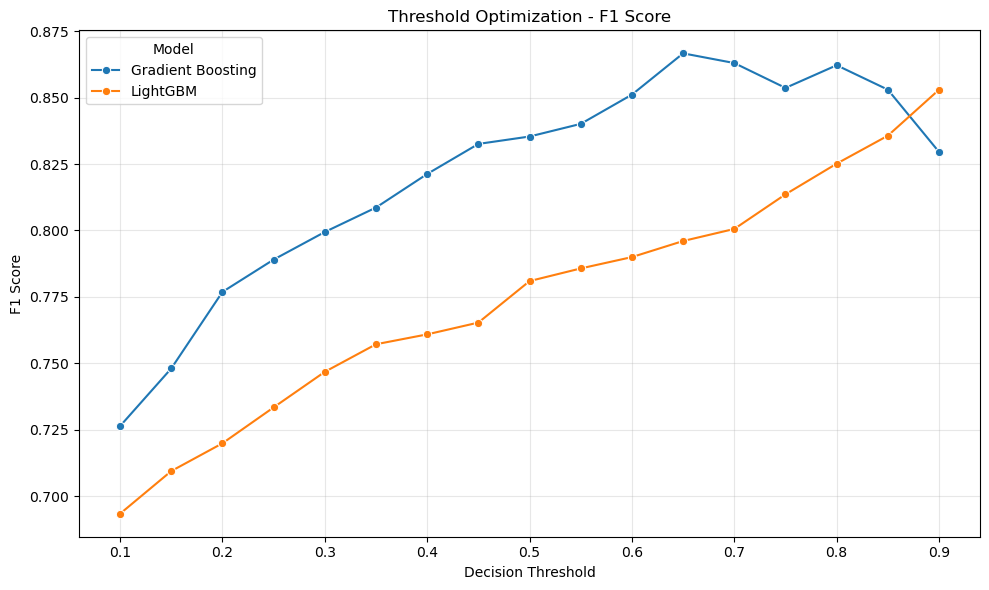

In [11]:

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=threshold_df,
    x="Threshold",
    y="F1",
    hue="Model",
    marker="o"
)

plt.title("Threshold Optimization - F1 Score")
plt.xlabel("Decision Threshold")
plt.ylabel("F1 Score")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [12]:

# Training verisini kronolojik olarak train ve validation'a ayır
validation_split_date = train_data["timestamp"].quantile(0.80)

fit_data = train_data[
    train_data["timestamp"] < validation_split_date
].copy()

validation_data = train_data[
    train_data["timestamp"] >= validation_split_date
].copy()

X_fit = fit_data[feature_columns]
y_fit = fit_data["is_fraud"]

X_val = validation_data[feature_columns]
y_val = validation_data["is_fraud"]

print("Fit data:", X_fit.shape)
print("Validation data:", X_val.shape)
print("Test data:", X_test.shape)

print("\nFraud counts:")
print("Fit:", y_fit.sum())
print("Validation:", y_val.sum())
print("Test:", y_test.sum())


Fit data: (63984, 17)
Validation data: (15996, 17)
Test data: (19995, 17)

Fraud counts:
Fit: 923
Validation: 277
Test: 299


In [13]:

validation_models = {}

for name in ["Gradient Boosting", "LightGBM"]:

    model = models[name]

    model.fit(X_fit, y_fit)

    validation_models[name] = model

    print(name, "trained successfully")


Gradient Boosting trained successfully
LightGBM trained successfully


In [14]:

validation_results = []

thresholds = np.arange(0.10, 0.96, 0.05)

for name, model in validation_models.items():

    probabilities = model.predict_proba(X_val)[:, 1]

    for threshold in thresholds:

        predicted = (
            probabilities >= threshold
        ).astype(int)

        validation_results.append({
            "Model": name,
            "Threshold": round(threshold, 2),
            "Precision": precision_score(
                y_val, predicted, zero_division=0
            ),
            "Recall": recall_score(
                y_val, predicted, zero_division=0
            ),
            "F1": f1_score(
                y_val, predicted, zero_division=0
            )
        })

validation_df = pd.DataFrame(validation_results)

best_thresholds = (
    validation_df.sort_values("F1", ascending=False)
    .groupby("Model")
    .head(1)
    .sort_values("F1", ascending=False)
)

display(best_thresholds)


,Model,Threshold,Precision,Recall,F1
35,LightGBM,0.95,0.830827,0.797834,0.813996
7,Gradient Boosting,0.45,0.783051,0.833935,0.807692


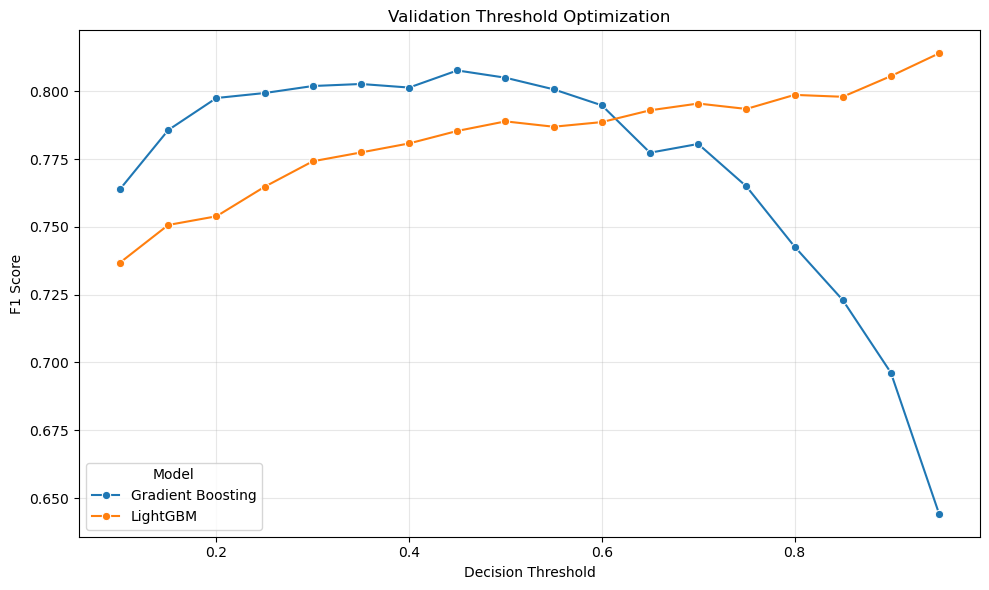

In [15]:

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=validation_df,
    x="Threshold",
    y="F1",
    hue="Model",
    marker="o"
)

plt.title("Validation Threshold Optimization")
plt.xlabel("Decision Threshold")
plt.ylabel("F1 Score")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [16]:
validation_split_date = train_data["timestamp"].quantile(0.80)

fit_data = train_data[
    train_data["timestamp"] < validation_split_date
].copy()

validation_data = train_data[
    train_data["timestamp"] >= validation_split_date
].copy()

X_fit = fit_data[feature_columns]
y_fit = fit_data["is_fraud"]

X_val = validation_data[feature_columns]
y_val = validation_data["is_fraud"]

print("Fit data:", X_fit.shape)
print("Validation data:", X_val.shape)
print("Test data:", X_test.shape)

print("\nFraud counts:")
print("Fit:", y_fit.sum())
print("Validation:", y_val.sum())
print("Test:", y_test.sum())


Fit data: (63984, 17)
Validation data: (15996, 17)
Test data: (19995, 17)

Fraud counts:
Fit: 923
Validation: 277
Test: 299


In [17]:

X_fit = fit_data[feature_columns]
y_fit = fit_data["is_fraud"]

X_val = validation_data[feature_columns]
y_val = validation_data["is_fraud"]

X_test = test_data[feature_columns]
y_test = test_data["is_fraud"]

print("All datasets prepared successfully!")


All datasets prepared successfully!


In [18]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from lightgbm import LGBMClassifier

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

import numpy as np
import pandas as pd

scale_pos_weight = (
    (y_fit == 0).sum() / (y_fit == 1).sum()
)

validation_models = {

    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", GradientBoostingClassifier(
            n_estimators=150,
            learning_rate=0.05,
            max_depth=3,
            min_samples_leaf=5,
            random_state=42
        ))
    ]),

    "LightGBM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", LGBMClassifier(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=8,
            num_leaves=31,
            scale_pos_weight=scale_pos_weight,
            verbosity=-1,
            random_state=42,
            n_jobs=-1
        ))
    ])
}

for name, model in validation_models.items():
    print(f"Training {name}...")
    model.fit(X_fit, y_fit)
    print("Completed!")


Training Gradient Boosting...
Completed!
Training LightGBM...
Completed!


In [19]:

validation_probabilities = {}

for name, model in validation_models.items():

    validation_probabilities[name] = (
        model.predict_proba(X_val)[:, 1]
    )

    print(
        name,
        "PR-AUC:",
        round(
            average_precision_score(
                y_val,
                validation_probabilities[name]
            ),
            4
        )
    )


Gradient Boosting PR-AUC: 0.8925
LightGBM PR-AUC: 0.909


In [20]:

thresholds = np.arange(0.10, 0.96, 0.05)

validation_results = []

for name, probabilities in validation_probabilities.items():

    for threshold in thresholds:

        predicted = (
            probabilities >= threshold
        ).astype(int)

        validation_results.append({
            "Model": name,
            "Threshold": round(threshold, 2),
            "Precision": precision_score(
                y_val, predicted, zero_division=0
            ),
            "Recall": recall_score(
                y_val, predicted, zero_division=0
            ),
            "F1": f1_score(
                y_val, predicted, zero_division=0
            )
        })

validation_df = pd.DataFrame(validation_results)

best_thresholds = (
    validation_df
    .sort_values("F1", ascending=False)
    .groupby("Model")
    .head(1)
    .sort_values("F1", ascending=False)
)

display(best_thresholds)


,Model,Threshold,Precision,Recall,F1
35,LightGBM,0.95,0.827068,0.794224,0.810313
7,Gradient Boosting,0.45,0.783051,0.833935,0.807692


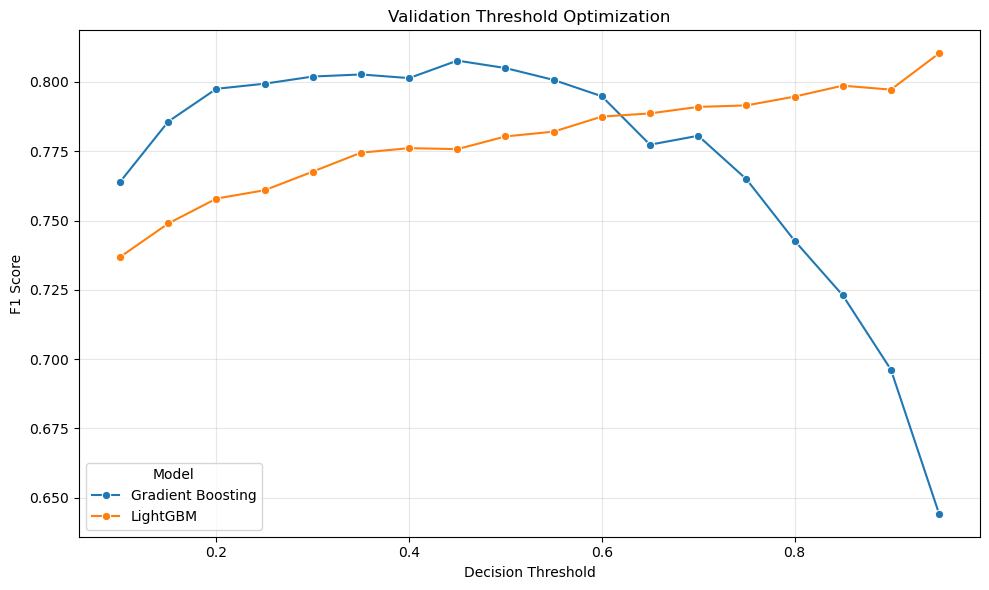

In [21]:

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=validation_df,
    x="Threshold",
    y="F1",
    hue="Model",
    marker="o"
)

plt.title("Validation Threshold Optimization")
plt.xlabel("Decision Threshold")
plt.ylabel("F1 Score")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [22]:
from pathlib import Path
import pandas as pd
import numpy as np

DATA_DIR = Path("../data/processed")

print("Directory exists:", DATA_DIR.exists())
print("Files:", [f.name for f in DATA_DIR.iterdir()])

Directory exists: True
Files: ['customers.csv', 'model_dataset.csv', 'all_transactions.csv', 'normal_transactions.csv']


In [23]:
raw_data = pd.read_csv(
    DATA_DIR / "all_transactions.csv"
)

model_raw = pd.read_csv(
    DATA_DIR / "model_dataset.csv"
)

print("Raw rows:", len(raw_data))
print("Model rows:", len(model_raw))

print(
    "Fraud labels match:",
    np.array_equal(
        raw_data["is_fraud"].values,
        model_raw["is_fraud"].values
    )
)

Raw rows: 99975
Model rows: 99975
Fraud labels match: True


In [24]:
print(
    "Transaction amounts match:",
    np.allclose(
        raw_data["amount"].values,
        model_raw["amount"].values
    )
)

print("\nRaw transaction IDs available:",
      "transaction_id" in raw_data.columns)

print("Model transaction IDs available:",
      "transaction_id" in model_raw.columns)

Transaction amounts match: False

Raw transaction IDs available: True
Model transaction IDs available: True


In [25]:

import pandas as pd
import numpy as np
from pathlib import Path

DATA_DIR = Path("../data/processed")

# Orijinal işlem verisini yükle
transactions = pd.read_csv(
    DATA_DIR / "all_transactions.csv"
)

transactions["timestamp"] = pd.to_datetime(
    transactions["timestamp"]
)

# Kronolojik sıralama
transactions = transactions.sort_values(
    "timestamp"
).reset_index(drop=True)

print("Dataset:", transactions.shape)
print("Unique transaction IDs:",
      transactions["transaction_id"].nunique())
print("Date range:",
      transactions["timestamp"].min(),
      "-",
      transactions["timestamp"].max())


Dataset: (99975, 12)
Unique transaction IDs: 99975
Date range: 2026-01-01 00:00:34.132897690 - 2026-01-30 23:59:43.756698067


In [26]:

transactions["amount_log"] = np.log1p(
    transactions["amount"]
)

transactions["hour"] = transactions["timestamp"].dt.hour

transactions["day_of_week"] = (
    transactions["timestamp"].dt.dayofweek
)

transactions["is_weekend"] = (
    transactions["day_of_week"] >= 5
).astype(int)

transactions["transaction_type_code"] = (
    transactions["transaction_type"]
    .astype("category")
    .cat.codes
)

print("Transaction features completed.")


Transaction features completed.


In [27]:

transactions["tx_count_1h"] = 0
transactions["tx_count_24h"] = 0
transactions["amount_sum_1h"] = 0.0
transactions["amount_sum_24h"] = 0.0

for sender_id, group in transactions.groupby("sender_id"):

    time_data = group.set_index("timestamp")

    transactions.loc[group.index, "tx_count_1h"] = (
        time_data["amount"]
        .rolling("1h", closed="left")
        .count()
        .to_numpy()
    )

    transactions.loc[group.index, "tx_count_24h"] = (
        time_data["amount"]
        .rolling("24h", closed="left")
        .count()
        .to_numpy()
    )

    transactions.loc[group.index, "amount_sum_1h"] = (
        time_data["amount"]
        .rolling("1h", closed="left")
        .sum()
        .to_numpy()
    )

    transactions.loc[group.index, "amount_sum_24h"] = (
        time_data["amount"]
        .rolling("24h", closed="left")
        .sum()
        .to_numpy()
    )

transactions["previous_avg_amount"] = (
    transactions.groupby("sender_id")["amount"]
    .transform(lambda x: x.shift(1).expanding().mean())
)

transactions["previous_std_amount"] = (
    transactions.groupby("sender_id")["amount"]
    .transform(lambda x: x.shift(1).expanding().std())
)

transactions["has_transaction_history"] = (
    transactions["previous_avg_amount"].notna()
).astype(int)

transactions["amount_vs_avg"] = (
    transactions["amount"] /
    transactions["previous_avg_amount"].replace(0, np.nan)
)

transactions["amount_zscore"] = (
    (transactions["amount"] - transactions["previous_avg_amount"])
    / transactions["previous_std_amount"].replace(0, np.nan)
)

transactions[
    ["amount_vs_avg", "amount_zscore"]
] = transactions[
    ["amount_vs_avg", "amount_zscore"]
].replace([np.inf, -np.inf], np.nan).fillna(0)

print("Behavioral features completed.")


Behavioral features completed.


In [28]:

transactions["sender_prior_tx_count"] = (
    transactions.groupby("sender_id").cumcount()
)

transactions["receiver_prior_tx_count"] = (
    transactions.groupby("receiver_id").cumcount()
)

print("Temporal graph features completed.")


Temporal graph features completed.


In [29]:

feature_columns = [
    "amount",
    "amount_log",
    "hour",
    "day_of_week",
    "is_weekend",
    "transaction_type_code",
    "tx_count_1h",
    "tx_count_24h",
    "amount_sum_1h",
    "amount_sum_24h",
    "previous_avg_amount",
    "previous_std_amount",
    "has_transaction_history",
    "amount_vs_avg",
    "amount_zscore",
    "sender_prior_tx_count",
    "receiver_prior_tx_count"
]

model_data = transactions[
    ["transaction_id", "timestamp"]
    + feature_columns
    + ["is_fraud"]
].copy()

model_data.to_csv(
    DATA_DIR / "model_dataset.csv",
    index=False
)

print("Model dataset saved:", model_data.shape)
print("Unique IDs:", model_data["transaction_id"].nunique())


Model dataset saved: (99975, 20)
Unique IDs: 99975


In [30]:

raw_data = pd.read_csv(
    DATA_DIR / "all_transactions.csv"
)

model_raw = pd.read_csv(
    DATA_DIR / "model_dataset.csv"
)

print(
    "Transaction IDs unique:",
    model_raw["transaction_id"].is_unique
)

print(
    "All transaction IDs preserved:",
    set(raw_data["transaction_id"]) ==
    set(model_raw["transaction_id"])
)

print(
    "Fraud labels preserved:",
    model_raw["is_fraud"].sum() ==
    raw_data["is_fraud"].sum()
)


Transaction IDs unique: True
All transaction IDs preserved: True
Fraud labels preserved: True


In [31]:

model_data = model_data.sort_values(
    "timestamp"
).reset_index(drop=True)

# Önce son %20'yi test olarak ayır
test_split_date = model_data["timestamp"].quantile(0.80)

train_validation = model_data[
    model_data["timestamp"] < test_split_date
].copy()

test_data = model_data[
    model_data["timestamp"] >= test_split_date
].copy()

# Kalan %80'in son %20'sini validation olarak ayır
validation_split_date = train_validation["timestamp"].quantile(0.80)

fit_data = train_validation[
    train_validation["timestamp"] < validation_split_date
].copy()

validation_data = train_validation[
    train_validation["timestamp"] >= validation_split_date
].copy()

print("FIT:", fit_data.shape)
print("VALIDATION:", validation_data.shape)
print("TEST:", test_data.shape)

print("\nFraud counts:")
print("Fit:", fit_data["is_fraud"].sum())
print("Validation:", validation_data["is_fraud"].sum())
print("Test:", test_data["is_fraud"].sum())

print("\nDate boundaries:")
print("Fit end:", fit_data["timestamp"].max())
print("Validation start:", validation_data["timestamp"].min())
print("Validation end:", validation_data["timestamp"].max())
print("Test start:", test_data["timestamp"].min())


FIT: (63984, 20)
VALIDATION: (15996, 20)
TEST: (19995, 20)

Fraud counts:
Fit: 923
Validation: 277
Test: 299

Date boundaries:
Fit end: 2026-01-20 05:16:40.705567949
Validation start: 2026-01-20 05:16:55.675555187
Validation end: 2026-01-24 23:21:29.093211014
Test start: 2026-01-24 23:21:57.994019054


In [32]:

feature_columns = [
    "amount",
    "amount_log",
    "hour",
    "day_of_week",
    "is_weekend",
    "transaction_type_code",
    "tx_count_1h",
    "tx_count_24h",
    "amount_sum_1h",
    "amount_sum_24h",
    "previous_avg_amount",
    "previous_std_amount",
    "has_transaction_history",
    "amount_vs_avg",
    "amount_zscore",
    "sender_prior_tx_count",
    "receiver_prior_tx_count"
]

X_fit = fit_data[feature_columns]
y_fit = fit_data["is_fraud"]

X_val = validation_data[feature_columns]
y_val = validation_data["is_fraud"]

X_test = test_data[feature_columns]
y_test = test_data["is_fraud"]

print("X_fit:", X_fit.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("\nMissing values in fit:", X_fit.isnull().sum().sum())
print("Missing values in validation:", X_val.isnull().sum().sum())
print("Missing values in test:", X_test.isnull().sum().sum())


X_fit: (63984, 17)
X_val: (15996, 17)
X_test: (19995, 17)

Missing values in fit: 247750
Missing values in validation: 54457
Missing values in test: 67767


In [33]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import GradientBoostingClassifier
from lightgbm import LGBMClassifier

scale_pos_weight = (
    (y_fit == 0).sum() /
    (y_fit == 1).sum()
)

validation_models = {
    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", GradientBoostingClassifier(
            n_estimators=150,
            learning_rate=0.05,
            max_depth=3,
            min_samples_leaf=5,
            random_state=42
        ))
    ]),

    "LightGBM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", LGBMClassifier(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=8,
            num_leaves=31,
            scale_pos_weight=scale_pos_weight,
            verbosity=-1,
            random_state=42,
            n_jobs=-1
        ))
    ])
}

for name, model in validation_models.items():
    print("Training:", name)
    model.fit(X_fit, y_fit)
    print("Completed!")


Training: Gradient Boosting
Completed!
Training: LightGBM
Completed!


In [34]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

thresholds = np.arange(0.10, 0.96, 0.05)

validation_results = []
validation_probabilities = {}

for name, model in validation_models.items():

    probabilities = model.predict_proba(X_val)[:, 1]
    validation_probabilities[name] = probabilities

    for threshold in thresholds:

        predicted = (
            probabilities >= threshold
        ).astype(int)

        validation_results.append({
            "Model": name,
            "Threshold": round(threshold, 2),
            "Precision": precision_score(
                y_val, predicted, zero_division=0
            ),
            "Recall": recall_score(
                y_val, predicted, zero_division=0
            ),
            "F1": f1_score(
                y_val, predicted, zero_division=0
            )
        })

validation_df = pd.DataFrame(validation_results)

best_thresholds = (
    validation_df
    .sort_values("F1", ascending=False)
    .groupby("Model")
    .head(1)
    .sort_values("F1", ascending=False)
)

display(best_thresholds)


,Model,Threshold,Precision,Recall,F1
35,LightGBM,0.95,0.827068,0.794224,0.810313
7,Gradient Boosting,0.45,0.783051,0.833935,0.807692


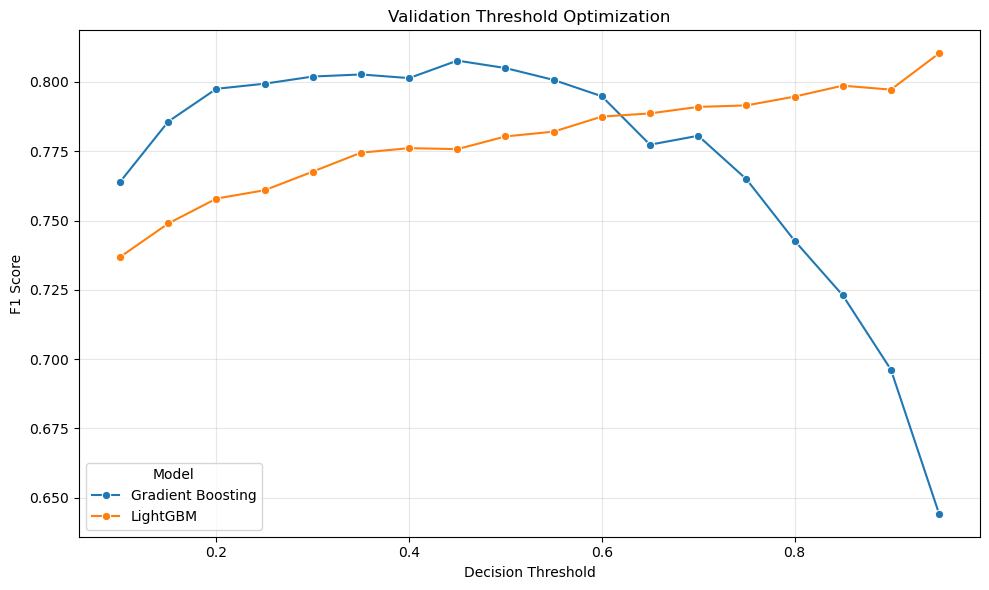

In [35]:

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=validation_df,
    x="Threshold",
    y="F1",
    hue="Model",
    marker="o"
)

plt.title("Validation Threshold Optimization")
plt.xlabel("Decision Threshold")
plt.ylabel("F1 Score")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [36]:
[key for key in globals().keys()
 if any(word in key.lower() for word in ["prob", "pred", "val"])]

['predictions',
 'y_probability',
 'y_prediction',
 'probabilities',
 'predicted',
 'validation_split_date',
 'validation_data',
 'X_val',
 'y_val',
 'validation_models',
 'validation_results',
 'validation_df',
 'validation_probabilities',
 'train_validation']

In [37]:
print(validation_probabilities.keys())

dict_keys(['Gradient Boosting', 'LightGBM'])


In [38]:
thresholds = np.arange(0.96, 1.00, 0.01)

lgbm_probs = np.asarray(validation_probabilities["LightGBM"])

results = []

for threshold in thresholds:
    y_pred = (lgbm_probs >= threshold).astype(int)

    results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall": recall_score(y_val, y_pred, zero_division=0),
        "F1": f1_score(y_val, y_pred, zero_division=0)
    })

lgbm_threshold_check = pd.DataFrame(results)

display(lgbm_threshold_check.sort_values("F1", ascending=False))

,Threshold,Precision,Recall,F1
1,0.97,0.848000,0.765343,0.804554
2,0.98,0.863071,0.750903,0.803089
0,0.96,0.832685,0.772563,0.801498
3,0.99,0.907834,0.711191,0.797571
4,1.00,0.000000,0.000000,0.000000


In [39]:
from sklearn.base import clone
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
import time

# Fit + Validation verilerini birleştir
X_train_final = pd.concat([X_fit, X_val])
y_train_final = pd.concat([y_fit, y_val])

# Validation aşamasında seçilen threshold değerleri
best_thresholds = {
    "Gradient Boosting": 0.45,
    "LightGBM": 0.95
}

final_results = []
final_predictions = {}

for model_name, pipeline in validation_models.items():

    print(f"\nTraining: {model_name}")

    start_time = time.time()

    final_model = clone(pipeline)
    final_model.fit(X_train_final, y_train_final)

    training_time = time.time() - start_time

    # Test olasılıkları
    test_probs = final_model.predict_proba(X_test)[:, 1]

    # Sabit validation threshold
    threshold = best_thresholds[model_name]
    test_preds = (test_probs >= threshold).astype(int)

    final_predictions[model_name] = test_preds

    final_results.append({
        "Model": model_name,
        "Threshold": threshold,
        "Precision": precision_score(y_test, test_preds, zero_division=0),
        "Recall": recall_score(y_test, test_preds, zero_division=0),
        "F1": f1_score(y_test, test_preds, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, test_probs),
        "PR_AUC": average_precision_score(y_test, test_probs),
        "Training_Time": round(training_time, 2)
    })

final_results_df = pd.DataFrame(final_results)

display(
    final_results_df.sort_values("F1", ascending=False)
)


Training: Gradient Boosting

Training: LightGBM


,Model,Threshold,Precision,Recall,F1,ROC_AUC,PR_AUC,Training_Time
1,LightGBM,0.95,0.871528,0.839465,0.855196,0.998693,0.937567,1.29
0,Gradient Boosting,0.45,0.758242,0.923077,0.832579,0.998747,0.943783,34.37


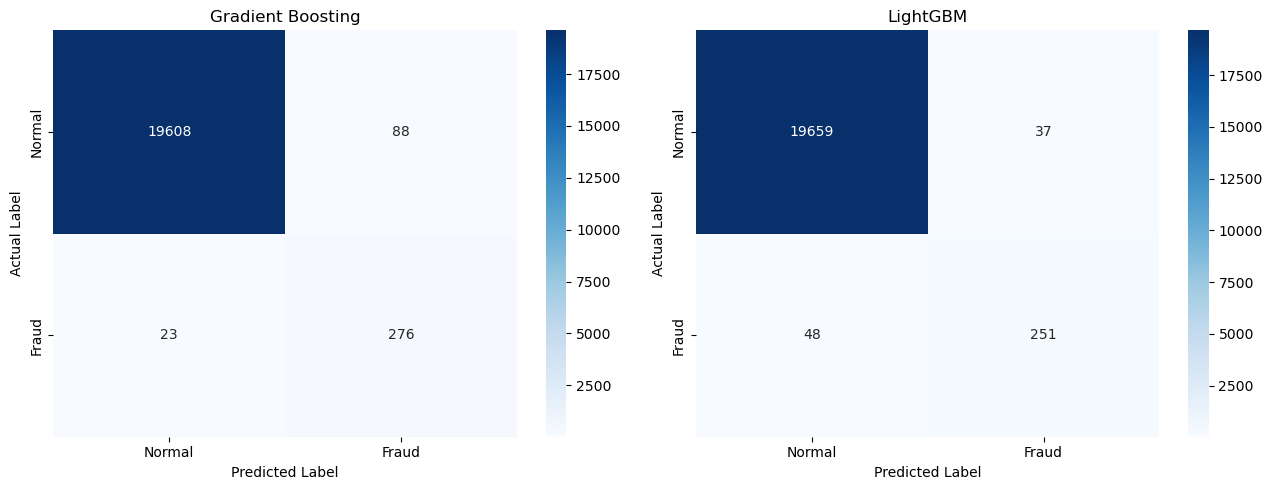

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, model_name in zip(axes, final_predictions.keys()):

    cm = confusion_matrix(
        y_test,
        final_predictions[model_name]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Normal", "Fraud"],
        yticklabels=["Normal", "Fraud"],
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

In [41]:
print(validation_models["LightGBM"])

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('model',
                 LGBMClassifier(learning_rate=0.05, max_depth=8,
                                n_estimators=300, n_jobs=-1, random_state=42,
                                scale_pos_weight=68.32177681473456,
                                verbosity=-1))])


In [42]:
%pip install shap

  Using cached numpy-2.5.5-cp312-cp312-macosx_10_13_x86_64.whl.metadata (6.6 kB)
Using cached numpy-2.5.5-cp312-cp312-macosx_10_13_x86_64.whl (14.8 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
Note: you may need to restart the kernel to use updated packages.


In [43]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.54.1


In [44]:
print(type(final_model.named_steps["model"]))

<class 'lightgbm.sklearn.LGBMClassifier'>


In [45]:
# Imputer ile test verisini dönüştür
X_test_imputed = final_model.named_steps["imputer"].transform(X_test)

# DataFrame olarak feature isimlerini koru
X_test_imputed = pd.DataFrame(
    X_test_imputed,
    columns=X_test.columns,
    index=X_test.index
)

# LightGBM modelini al
lgbm_model = final_model.named_steps["model"]

# SHAP explainer
explainer = shap.TreeExplainer(lgbm_model)

# SHAP değerleri
shap_values = explainer(X_test_imputed)

print("SHAP values shape:", shap_values.values.shape)

SHAP values shape: (19995, 17)


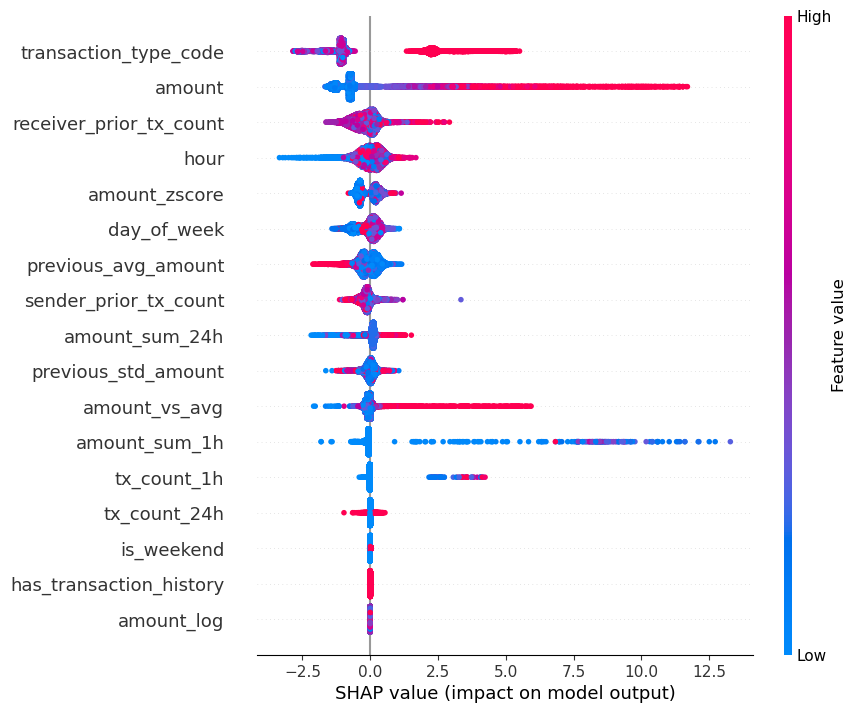

In [46]:
shap.plots.beeswarm(
    shap_values,
    max_display=17
)

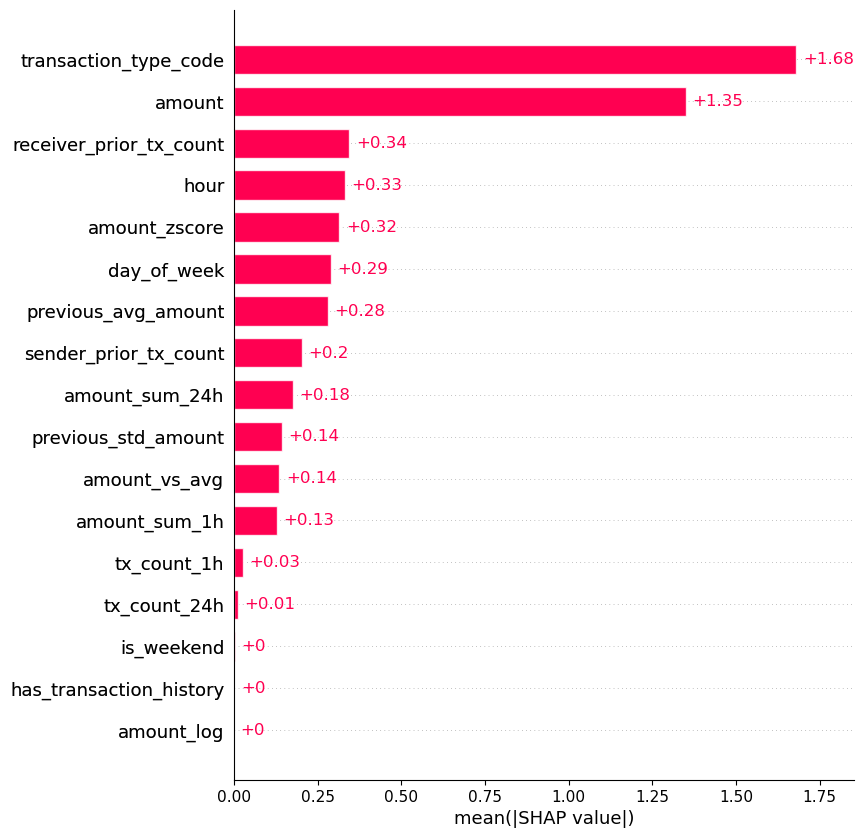

In [47]:
shap.plots.bar(
    shap_values,
    max_display=17
)

In [48]:
shap_importance = pd.DataFrame({
    "Feature": X_test_imputed.columns,
    "Mean_SHAP": np.abs(shap_values.values).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    "Mean_SHAP",
    ascending=False
)

display(shap_importance.head(10))

,Feature,Mean_SHAP
5,transaction_type_code,1.679967
0,amount,1.349540
16,receiver_prior_tx_count,0.344914
2,hour,0.330463
14,amount_zscore,0.315121
3,day_of_week,0.288838
10,previous_avg_amount,0.279898
15,sender_prior_tx_count,0.202278
9,amount_sum_24h,0.175783
11,previous_std_amount,0.141995


In [49]:
# LightGBM'in doğru yakaladığı fraud işlemlerini bul
lgbm_preds = final_predictions["LightGBM"]

true_positive_indices = np.where(
    (np.asarray(y_test) == 1) &
    (lgbm_preds == 1)
)[0]

print("Correctly detected fraud:", len(true_positive_indices))

Correctly detected fraud: 251


In [50]:
# İlk doğru yakalanan fraud işlemi
sample_idx = true_positive_indices[0]

print("Test row position:", sample_idx)
print("Actual label:", np.asarray(y_test)[sample_idx])
print("Predicted label:", lgbm_preds[sample_idx])
print("Fraud probability:", 
      validation_results if False else 
      "Bir sonraki adımda hesaplayacağız")

Test row position: 127
Actual label: 1
Predicted label: 1
Fraud probability: Bir sonraki adımda hesaplayacağız


In [51]:
# Seçilen işlemin fraud olasılığı
lgbm_test_probs = lgbm_model.predict_proba(X_test_imputed)[:, 1]

fraud_probability = lgbm_test_probs[sample_idx]

print(f"Fraud Probability: {fraud_probability:.4f}")
print(f"Fraud Probability (%): {fraud_probability * 100:.2f}%")
print(f"Decision Threshold: 0.95")

Fraud Probability: 0.9995
Fraud Probability (%): 99.95%
Decision Threshold: 0.95


In [52]:
# Seçilen işlemin SHAP katkıları
local_explanation = pd.DataFrame({
    "Feature": X_test_imputed.columns,
    "Feature_Value": X_test_imputed.iloc[sample_idx].values,
    "SHAP_Value": shap_values.values[sample_idx]
})

local_explanation["Absolute_SHAP"] = (
    local_explanation["SHAP_Value"].abs()
)

local_explanation = local_explanation.sort_values(
    "Absolute_SHAP",
    ascending=False
)

display(local_explanation.head(10))

,Feature,Feature_Value,SHAP_Value,Absolute_SHAP
0,amount,1732.880000,9.808653,9.808653
13,amount_vs_avg,97.847544,5.241651,5.241651
5,transaction_type_code,3.000000,4.876907,4.876907
15,sender_prior_tx_count,7.000000,3.345107,3.345107
2,hour,0.000000,-1.122367,1.122367
3,day_of_week,6.000000,-0.923896,0.923896
10,previous_avg_amount,17.710000,-0.625882,0.625882
11,previous_std_amount,7.623569,-0.419712,0.419712
16,receiver_prior_tx_count,5.000000,0.234313,0.234313
14,amount_zscore,224.982559,-0.180989,0.180989


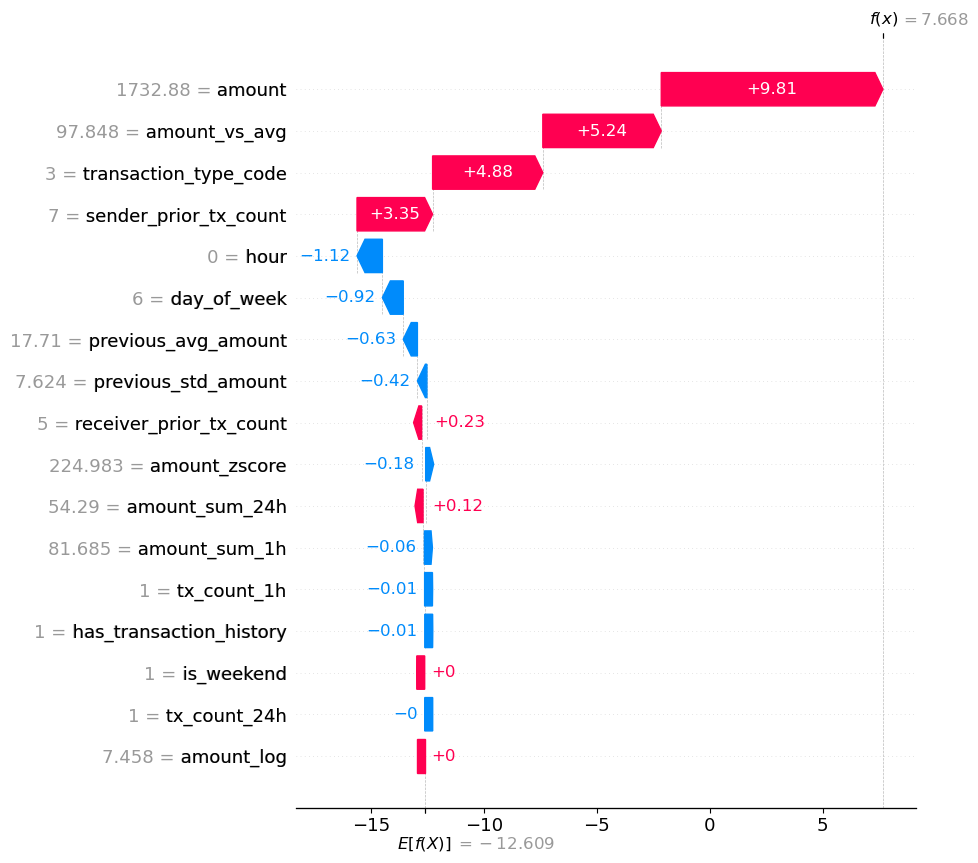

In [53]:
shap.plots.waterfall(
    shap_values[sample_idx],
    max_display=17
)

In [54]:
import pandas as pd

all_transactions = pd.read_csv(
    "../data/processed/all_transactions.csv"
)

print("Dataset shape:", all_transactions.shape)
print("Columns:")
print(all_transactions.columns.tolist())

Dataset shape: (99975, 12)
Columns:
['transaction_id', 'timestamp', 'sender_id', 'receiver_id', 'transaction_type', 'amount', 'sender_balance_before', 'sender_balance_after', 'device_id', 'location', 'is_fraud', 'fraud_scenario']


In [55]:
print(all_transactions["fraud_scenario"].value_counts())

fraud_scenario
NORMAL                98476
UNUSUAL_AMOUNT          300
RAPID_TRANSACTIONS      300
COORDINATED_FRAUD       300
MONEY_LAUNDERING        300
ACCOUNT_TAKEOVER        299
Name: count, dtype: int64


In [56]:
import networkx as nx

G = nx.from_pandas_edgelist(
    all_transactions,
    source="sender_id",
    target="receiver_id",
    edge_attr=["amount", "fraud_scenario"],
    create_using=nx.DiGraph()
)

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

Nodes: 10000
Edges: 99925


In [57]:
print("G exists:", "G" in globals())

if "G" in globals():
    print("Nodes:", G.number_of_nodes())
    print("Edges:", G.number_of_edges())

G exists: True
Nodes: 10000
Edges: 99925


In [58]:
# Community detection için undirected graph
G_undirected = G.to_undirected()

# Louvain community detection
communities = nx.community.louvain_communities(
    G_undirected,
    seed=42
)

# Hesap-community eşleştirmesi
community_mapping = {}

for community_id, members in enumerate(communities):
    for account_id in members:
        community_mapping[account_id] = community_id

account_communities = pd.DataFrame({
    "account_id": list(community_mapping.keys()),
    "community_id": list(community_mapping.values())
})

print("Number of communities:", len(communities))
print("Accounts assigned:", len(account_communities))

display(
    account_communities["community_id"]
    .value_counts()
    .head(10)
)

Number of communities: 12
Accounts assigned: 10000


community_id
1     1397
4     1379
10    1121
2     1101
0     1100
3     1094
7     1092
9      724
8      309
11     258
Name: count, dtype: int64

In [59]:
# Her işlemi gönderici hesabının community'siyle eşleştir
transactions_with_community = all_transactions.merge(
    account_communities,
    left_on="sender_id",
    right_on="account_id",
    how="left"
)

# Community bazında fraud dağılımı
community_fraud = (
    transactions_with_community
    .groupby("community_id")
    .agg(
        total_transactions=("is_fraud", "count"),
        fraud_transactions=("is_fraud", "sum"),
        unique_senders=("sender_id", "nunique"),
        fraud_rate=("is_fraud", "mean")
    )
    .reset_index()
)

community_fraud["fraud_rate_pct"] = (
    community_fraud["fraud_rate"] * 100
)

community_fraud = community_fraud.sort_values(
    "fraud_rate_pct",
    ascending=False
)

display(
    community_fraud.drop(columns="fraud_rate")
)

,community_id,total_transactions,fraud_transactions,unique_senders,fraud_rate_pct
5,5,2164,64,217,2.957486
11,11,2606,50,258,1.918649
4,4,13903,249,1379,1.790980
3,3,10866,180,1094,1.656543
9,9,7314,120,724,1.640689
10,10,11150,174,1121,1.560538
6,6,2068,30,208,1.450677
2,2,10983,152,1101,1.383957
1,1,13915,183,1397,1.315128
0,0,11008,142,1100,1.289971


In [60]:
scenario_community = (
    transactions_with_community
    .pivot_table(
        index="community_id",
        columns="fraud_scenario",
        values="transaction_id",
        aggfunc="count",
        fill_value=0
    )
)

display(
    scenario_community.sort_values(
        "COORDINATED_FRAUD",
        ascending=False
    )
)

fraud_scenario,ACCOUNT_TAKEOVER,COORDINATED_FRAUD,MONEY_LAUNDERING,NORMAL,RAPID_TRANSACTIONS,UNUSUAL_AMOUNT
community_id,,,,,,
4,50,47,46,13654,60,46
0,15,38,30,10866,30,29
1,25,38,51,13732,30,39
2,25,34,35,10831,20,38
10,45,34,35,10976,30,30
7,14,31,23,10819,30,23
3,30,30,26,10686,50,44
9,20,19,17,7194,40,24
11,15,9,12,2556,10,4


In [61]:
scenario_rates = scenario_community.copy()

scenario_rates["total_transactions"] = (
    scenario_rates.sum(axis=1)
)

scenario_rates["coordinated_fraud_rate"] = (
    scenario_rates["COORDINATED_FRAUD"] /
    scenario_rates["total_transactions"] * 100
)

scenario_rates["money_laundering_rate"] = (
    scenario_rates["MONEY_LAUNDERING"] /
    scenario_rates["total_transactions"] * 100
)

scenario_rates["total_fraud_rate"] = (
    scenario_rates.drop(
        columns=["NORMAL", "total_transactions",
                 "coordinated_fraud_rate",
                 "money_laundering_rate"]
    ).sum(axis=1) /
    scenario_rates["total_transactions"] * 100
)

display(
    scenario_rates[
        [
            "total_transactions",
            "coordinated_fraud_rate",
            "money_laundering_rate",
            "total_fraud_rate"
        ]
    ].sort_values(
        "coordinated_fraud_rate",
        ascending=False
    )
)

fraud_scenario,total_transactions,coordinated_fraud_rate,money_laundering_rate,total_fraud_rate
community_id,,,,
11,2606,0.345357,0.460476,1.918649
0,11008,0.345203,0.272529,1.289971
6,2068,0.338491,0.386847,1.450677
4,13903,0.338057,0.330864,1.790980
2,10983,0.309569,0.318674,1.383957
10,11150,0.304933,0.313901,1.560538
7,10940,0.283364,0.210238,1.106033
3,10866,0.276091,0.239278,1.656543
1,13915,0.273087,0.366511,1.315128


In [62]:
# Community 3 işlemlerini seç
community_3 = transactions_with_community[
    transactions_with_community["community_id"] == 3
].copy()

# Gönderici hesap bazında investigation
suspicious_accounts = (
    community_3
    .groupby("sender_id")
    .agg(
        total_transactions=("transaction_id", "count"),
        fraud_transactions=("is_fraud", "sum"),
        total_amount=("amount", "sum"),
        avg_amount=("amount", "mean"),
        coordinated_fraud=(
            "fraud_scenario",
            lambda x: (x == "COORDINATED_FRAUD").sum()
        ),
        money_laundering=(
            "fraud_scenario",
            lambda x: (x == "MONEY_LAUNDERING").sum()
        )
    )
    .reset_index()
)

suspicious_accounts["fraud_rate"] = (
    suspicious_accounts["fraud_transactions"] /
    suspicious_accounts["total_transactions"] * 100
)

# En az 3 işlem yapan hesapları incele
suspicious_accounts = suspicious_accounts[
    suspicious_accounts["total_transactions"] >= 3
]

suspicious_accounts = suspicious_accounts.sort_values(
    ["fraud_transactions", "fraud_rate"],
    ascending=False
)

display(suspicious_accounts.head(15))

,sender_id,total_transactions,fraud_transactions,total_amount,avg_amount,coordinated_fraud,money_laundering,fraud_rate
307,ACC_002700,21,11,5869.23,279.487143,0,1,52.380952
645,ACC_005777,14,10,3597.80,256.985714,0,0,71.428571
1052,ACC_009721,17,10,4657.70,273.982353,0,0,58.823529
84,ACC_000664,18,10,2961.60,164.533333,0,0,55.555556
338,ACC_003011,21,10,3991.85,190.088095,0,0,47.619048
480,ACC_004281,12,5,6394.82,532.901667,0,0,41.666667
624,ACC_005599,13,5,6736.24,518.172308,0,0,38.461538
971,ACC_008815,14,5,8150.70,582.192857,0,0,35.714286
677,ACC_006142,16,5,5353.67,334.604375,0,0,31.250000
1071,ACC_009865,18,5,6676.28,370.904444,0,0,27.777778


In [63]:
# İncelenecek hesap
target_account = "ACC_002755"

# Hesabın gönderdiği işlemler
outgoing = all_transactions[
    all_transactions["sender_id"] == target_account
].copy()

# Hesabın aldığı işlemler
incoming = all_transactions[
    all_transactions["receiver_id"] == target_account
].copy()

print("ACCOUNT:", target_account)
print("Outgoing transactions:", len(outgoing))
print("Incoming transactions:", len(incoming))

print("\nFraud scenario distribution:")
display(outgoing["fraud_scenario"].value_counts())

print("\nOutgoing transaction details:")
display(
    outgoing[
        [
            "timestamp",
            "receiver_id",
            "amount",
            "fraud_scenario",
            "is_fraud"
        ]
    ].sort_values("timestamp")
)

ACCOUNT: ACC_002755
Outgoing transactions: 17
Incoming transactions: 14

Fraud scenario distribution:


fraud_scenario
RAPID_TRANSACTIONS    10
NORMAL                 6
UNUSUAL_AMOUNT         1
Name: count, dtype: int64


Outgoing transaction details:


,timestamp,receiver_id,amount,fraud_scenario,is_fraud
1132,2026-01-01 07:42:46.667401111,ACC_002950,505.95,NORMAL,0
37410,2026-01-12 07:08:27.165311957,ACC_001374,118.99,NORMAL,0
46171,2026-01-14 22:20:45.887002751,ACC_009927,121.11,NORMAL,0
54654,2026-01-17 10:48:33.563018854,ACC_007019,37.80,NORMAL,0
65096,2026-01-20 13:13:31.329550927,ACC_001371,71.23,NORMAL,0
68862,2026-01-21 16:11:37.000000000,ACC_006309,176.64,RAPID_TRANSACTIONS,1
68863,2026-01-21 16:11:41.000000000,ACC_005315,466.94,RAPID_TRANSACTIONS,1
68866,2026-01-21 16:12:17.000000000,ACC_004483,102.93,RAPID_TRANSACTIONS,1
68867,2026-01-21 16:12:52.000000000,ACC_003389,470.98,RAPID_TRANSACTIONS,1
68868,2026-01-21 16:13:06.000000000,ACC_005048,440.11,RAPID_TRANSACTIONS,1


In [64]:
print("TOP RECEIVERS")

display(
    outgoing.groupby("receiver_id")
    .agg(
        transaction_count=("transaction_id", "count"),
        total_amount=("amount", "sum"),
        fraud_transactions=("is_fraud", "sum")
    )
    .sort_values("transaction_count", ascending=False)
    .head(10)
)

print("TOP SENDERS")

display(
    incoming.groupby("sender_id")
    .agg(
        transaction_count=("transaction_id", "count"),
        total_amount=("amount", "sum")
    )
    .sort_values("transaction_count", ascending=False)
    .head(10)
)

TOP RECEIVERS


,transaction_count,total_amount,fraud_transactions
receiver_id,,,
ACC_000249,1,223.01,1
ACC_005315,1,466.94,1
ACC_009875,1,10000.00,1
ACC_008521,1,463.82,1
ACC_007019,1,37.80,0
ACC_006309,1,176.64,1
ACC_005872,1,299.53,1
ACC_005670,1,221.62,0
ACC_005048,1,440.11,1


TOP SENDERS


,transaction_count,total_amount
sender_id,,
ACC_000959,1,117.11
ACC_000977,1,12.76
ACC_002239,1,36.88
ACC_002765,1,152.58
ACC_005034,1,49.28
ACC_005439,1,109.28
ACC_006416,1,6.92
ACC_006786,1,96.74
ACC_007102,1,40.37


In [65]:
# Hesabın bütün gönderdiği işlemlerin senaryo dağılımı
display(
    outgoing.groupby("fraud_scenario")
    .agg(
        transaction_count=("transaction_id", "count"),
        total_amount=("amount", "sum"),
        average_amount=("amount", "mean")
    )
    .sort_values("transaction_count", ascending=False)
)

,transaction_count,total_amount,average_amount
fraud_scenario,,,
RAPID_TRANSACTIONS,10,2956.95,295.695
NORMAL,6,1076.70,179.450
UNUSUAL_AMOUNT,1,10000.00,10000.000


In [66]:
display(
    outgoing[
        [
            "transaction_id",
            "timestamp",
            "receiver_id",
            "amount",
            "fraud_scenario",
            "is_fraud"
        ]
    ]
    .sort_values("amount", ascending=False)
    .head(10)
)

,transaction_id,timestamp,receiver_id,amount,fraud_scenario,is_fraud
69425,UNUSUAL_00044,2026-01-21 20:05:41.000000000,ACC_009875,10000.00,UNUSUAL_AMOUNT,1
1132,TXN_0001112,2026-01-01 07:42:46.667401111,ACC_002950,505.95,NORMAL,0
68867,RAPID_ACC_002755_008,2026-01-21 16:12:52.000000000,ACC_003389,470.98,RAPID_TRANSACTIONS,1
68863,RAPID_ACC_002755_005,2026-01-21 16:11:41.000000000,ACC_005315,466.94,RAPID_TRANSACTIONS,1
68872,RAPID_ACC_002755_001,2026-01-21 16:13:25.000000000,ACC_008521,463.82,RAPID_TRANSACTIONS,1
68868,RAPID_ACC_002755_002,2026-01-21 16:13:06.000000000,ACC_005048,440.11,RAPID_TRANSACTIONS,1
68874,RAPID_ACC_002755_003,2026-01-21 16:13:30.000000000,ACC_005872,299.53,RAPID_TRANSACTIONS,1
68879,RAPID_ACC_002755_009,2026-01-21 16:15:02.000000000,ACC_000249,223.01,RAPID_TRANSACTIONS,1
74306,TXN_0073234,2026-01-23 07:04:49.511869138,ACC_005670,221.62,NORMAL,0
68862,RAPID_ACC_002755_007,2026-01-21 16:11:37.000000000,ACC_006309,176.64,RAPID_TRANSACTIONS,1


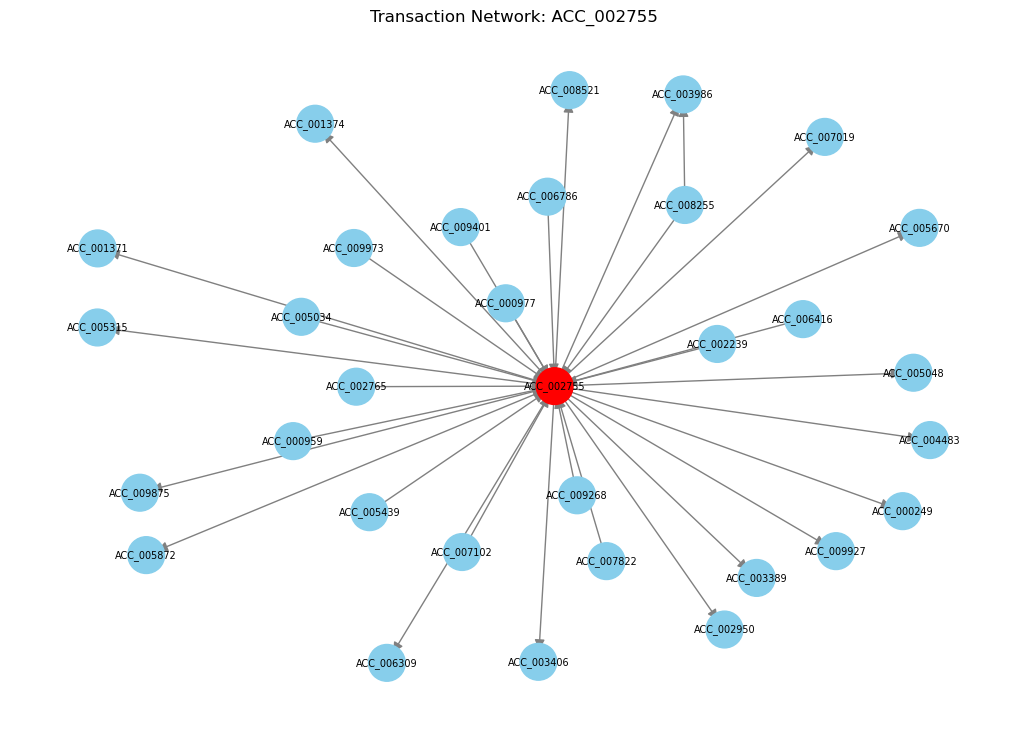

In [67]:
import matplotlib.pyplot as plt

# Hedef hesap ve birinci derece bağlantıları
neighbors = set(G.successors(target_account)) | set(
    G.predecessors(target_account)
)

ego_nodes = neighbors | {target_account}
ego_graph = G.subgraph(ego_nodes).copy()

plt.figure(figsize=(13, 9))

pos = nx.spring_layout(
    ego_graph,
    seed=42,
    k=0.8
)

node_colors = [
    "red" if node == target_account else "skyblue"
    for node in ego_graph.nodes()
]

nx.draw_networkx_nodes(
    ego_graph, pos,
    node_color=node_colors,
    node_size=700
)

nx.draw_networkx_edges(
    ego_graph, pos,
    edge_color="gray",
    arrows=True,
    arrowsize=15
)

nx.draw_networkx_labels(
    ego_graph, pos,
    font_size=7
)

plt.title(f"Transaction Network: {target_account}")
plt.axis("off")
plt.show()

In [68]:
# Account network statistics
in_degree = G.in_degree(target_account)
out_degree = G.out_degree(target_account)

print("Account:", target_account)
print("Incoming connections:", in_degree)
print("Outgoing connections:", out_degree)
print("Total degree:", in_degree + out_degree)

# Unique counterparties
incoming_accounts = set(G.predecessors(target_account))
outgoing_accounts = set(G.successors(target_account))

print("\nUnique incoming accounts:", len(incoming_accounts))
print("Unique outgoing accounts:", len(outgoing_accounts))
print("Accounts in both directions:", len(incoming_accounts & outgoing_accounts))

# Transaction scenario distribution
print("\nOutgoing transaction scenarios:")
display(
    outgoing["fraud_scenario"]
    .value_counts()
    .rename_axis("scenario")
    .reset_index(name="count")
)

print("\nIncoming transaction scenarios:")
display(
    incoming["fraud_scenario"]
    .value_counts()
    .rename_axis("scenario")
    .reset_index(name="count")
)

Account: ACC_002755
Incoming connections: 14
Outgoing connections: 17
Total degree: 31

Unique incoming accounts: 14
Unique outgoing accounts: 17
Accounts in both directions: 0

Outgoing transaction scenarios:


,scenario,count
0,RAPID_TRANSACTIONS,10
1,NORMAL,6
2,UNUSUAL_AMOUNT,1



Incoming transaction scenarios:


,scenario,count
0,NORMAL,14


In [69]:
import pandas as pd

# Network metrics
incoming_accounts = set(G.predecessors(target_account))
outgoing_accounts = set(G.successors(target_account))

network_metrics = {
    "account_id": target_account,
    "incoming_transactions": len(incoming),
    "outgoing_transactions": len(outgoing),
    "unique_incoming_accounts": len(incoming_accounts),
    "unique_outgoing_accounts": len(outgoing_accounts),
    "mutual_connections": len(incoming_accounts & outgoing_accounts)
}

# Transaction metrics
transaction_metrics = {
    "total_transactions": len(outgoing) + len(incoming),
    "outgoing_fraud_count": int(outgoing["is_fraud"].sum()),
    "incoming_fraud_count": int(incoming["is_fraud"].sum()),
    "outgoing_total_amount": round(outgoing["amount"].sum(), 2),
    "incoming_total_amount": round(incoming["amount"].sum(), 2)
}

# Fraud scenario distribution
scenario_distribution = (
    outgoing.groupby("fraud_scenario")
    .agg(
        transaction_count=("transaction_id", "count"),
        total_amount=("amount", "sum"),
        fraud_count=("is_fraud", "sum")
    )
    .sort_values("transaction_count", ascending=False)
    .reset_index()
)

print("NETWORK METRICS")
display(pd.DataFrame([network_metrics]))

print("TRANSACTION METRICS")
display(pd.DataFrame([transaction_metrics]))

print("OUTGOING FRAUD SCENARIOS")
display(scenario_distribution)

NETWORK METRICS


,account_id,incoming_transactions,outgoing_transactions,unique_incoming_accounts,unique_outgoing_accounts,mutual_connections
0,ACC_002755,14,17,14,17,0


TRANSACTION METRICS


,total_transactions,outgoing_fraud_count,incoming_fraud_count,outgoing_total_amount,incoming_total_amount
0,31,11,0,14033.65,1204.76


OUTGOING FRAUD SCENARIOS


,fraud_scenario,transaction_count,total_amount,fraud_count
0,RAPID_TRANSACTIONS,10,2956.95,10
1,NORMAL,6,1076.70,0
2,UNUSUAL_AMOUNT,1,10000.00,1


In [70]:
# Outgoing transactions timeline
outgoing_timeline = outgoing[
    [
        "transaction_id",
        "timestamp",
        "receiver_id",
        "amount",
        "fraud_scenario",
        "is_fraud"
    ]
].sort_values("timestamp")

display(outgoing_timeline)

,transaction_id,timestamp,receiver_id,amount,fraud_scenario,is_fraud
1132,TXN_0001112,2026-01-01 07:42:46.667401111,ACC_002950,505.95,NORMAL,0
37410,TXN_0036940,2026-01-12 07:08:27.165311957,ACC_001374,118.99,NORMAL,0
46171,TXN_0045540,2026-01-14 22:20:45.887002751,ACC_009927,121.11,NORMAL,0
54654,TXN_0053868,2026-01-17 10:48:33.563018854,ACC_007019,37.80,NORMAL,0
65096,TXN_0064187,2026-01-20 13:13:31.329550927,ACC_001371,71.23,NORMAL,0
68862,RAPID_ACC_002755_007,2026-01-21 16:11:37.000000000,ACC_006309,176.64,RAPID_TRANSACTIONS,1
68863,RAPID_ACC_002755_005,2026-01-21 16:11:41.000000000,ACC_005315,466.94,RAPID_TRANSACTIONS,1
68866,RAPID_ACC_002755_010,2026-01-21 16:12:17.000000000,ACC_004483,102.93,RAPID_TRANSACTIONS,1
68867,RAPID_ACC_002755_008,2026-01-21 16:12:52.000000000,ACC_003389,470.98,RAPID_TRANSACTIONS,1
68868,RAPID_ACC_002755_002,2026-01-21 16:13:06.000000000,ACC_005048,440.11,RAPID_TRANSACTIONS,1


In [71]:
# Convert timestamp strings to datetime
outgoing_timeline["timestamp"] = pd.to_datetime(
    outgoing_timeline["timestamp"]
)

# Calculate time gaps
outgoing_timeline["time_gap_minutes"] = (
    outgoing_timeline["timestamp"]
    .diff()
    .dt.total_seconds() / 60
)

display(
    outgoing_timeline[
        [
            "timestamp",
            "receiver_id",
            "amount",
            "fraud_scenario",
            "time_gap_minutes"
        ]
    ]
)

,timestamp,receiver_id,amount,fraud_scenario,time_gap_minutes
1132,2026-01-01 07:42:46.667401111,ACC_002950,505.95,NORMAL,NaN
37410,2026-01-12 07:08:27.165311957,ACC_001374,118.99,NORMAL,15805.674965
46171,2026-01-14 22:20:45.887002751,ACC_009927,121.11,NORMAL,3792.312028
54654,2026-01-17 10:48:33.563018854,ACC_007019,37.80,NORMAL,3627.794600
65096,2026-01-20 13:13:31.329550927,ACC_001371,71.23,NORMAL,4464.962776
68862,2026-01-21 16:11:37.000000000,ACC_006309,176.64,RAPID_TRANSACTIONS,1618.094507
68863,2026-01-21 16:11:41.000000000,ACC_005315,466.94,RAPID_TRANSACTIONS,0.066667
68866,2026-01-21 16:12:17.000000000,ACC_004483,102.93,RAPID_TRANSACTIONS,0.600000
68867,2026-01-21 16:12:52.000000000,ACC_003389,470.98,RAPID_TRANSACTIONS,0.583333
68868,2026-01-21 16:13:06.000000000,ACC_005048,440.11,RAPID_TRANSACTIONS,0.233333


In [72]:
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nX_test index sample:")
print(X_test.index[:5])

print("\nAvailable DataFrames:")
for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(name, obj.shape)

X_test shape: (19995, 17)
y_test shape: (19995,)

X_test index sample:
Index([79980, 79981, 79982, 79983, 79984], dtype='int64')

Available DataFrames:
transactions (99975, 28)
model_data (99975, 20)
train_data (79980, 20)
test_data (19995, 20)
X_train (79980, 17)
X_test (19995, 17)
results_df (4, 8)
threshold_df (34, 5)
fit_data (63984, 20)
validation_data (15996, 20)
X_fit (63984, 17)
X_val (15996, 17)
validation_df (36, 5)
raw_data (99975, 12)
model_raw (99975, 20)
group (7, 21)
time_data (7, 20)
train_validation (79980, 20)
lgbm_threshold_check (5, 4)
X_train_final (79980, 17)
final_results_df (2, 8)
X_test_imputed (19995, 17)
shap_importance (17, 2)
local_explanation (17, 4)
all_transactions (99975, 12)
account_communities (10000, 2)
transactions_with_community (99975, 14)
community_fraud (12, 6)
scenario_community (12, 6)
scenario_rates (12, 10)
community_3 (10866, 14)
suspicious_accounts (1091, 8)
outgoing (17, 12)
incoming (14, 12)
scenario_distribution (3, 4)
outgoing_timeline

In [73]:
# Check available model variables
for name, obj in globals().copy().items():
    if "model" in name.lower() or "lgbm" in name.lower():
        print(name, type(obj))

MODEL_PATH <class 'pathlib.PosixPath'>
model_data <class 'pandas.core.frame.DataFrame'>
LGBMClassifier <class 'type'>
models <class 'dict'>
trained_models <class 'dict'>
model <class 'sklearn.pipeline.Pipeline'>
model_name <class 'str'>
validation_models <class 'dict'>
model_raw <class 'pandas.core.frame.DataFrame'>
lgbm_probs <class 'numpy.ndarray'>
lgbm_threshold_check <class 'pandas.core.frame.DataFrame'>
final_model <class 'sklearn.pipeline.Pipeline'>
lgbm_model <class 'lightgbm.sklearn.LGBMClassifier'>
lgbm_preds <class 'numpy.ndarray'>
lgbm_test_probs <class 'numpy.ndarray'>


In [74]:
# Find all objects that support prediction
for name, obj in globals().copy().items():
    if hasattr(obj, "predict") and callable(obj.predict):
        print(name, type(obj))

# Check saved model files
import os

print("\nModels directory:")
print(os.listdir("../models"))

Pipeline <class 'abc.ABCMeta'>
LogisticRegression <class 'type'>
RandomForestClassifier <class 'abc.ABCMeta'>
LGBMClassifier <class 'type'>
GradientBoostingClassifier <class 'abc.ABCMeta'>
model <class 'sklearn.pipeline.Pipeline'>
pipeline <class 'sklearn.pipeline.Pipeline'>
final_model <class 'sklearn.pipeline.Pipeline'>
lgbm_model <class 'lightgbm.sklearn.LGBMClassifier'>

Models directory:
['y_train.pkl', 'X_test.pkl', 'y_test.pkl', 'test_data.pkl', 'X_train.pkl', 'lightgbm_model.pkl']


In [75]:
print(final_results_df)


               Model  Threshold  Precision    Recall        F1   ROC_AUC  \
0  Gradient Boosting       0.45   0.758242  0.923077  0.832579  0.998747   
1           LightGBM       0.95   0.871528  0.839465  0.855196  0.998693   

     PR_AUC  Training_Time  
0  0.943783          34.37  
1  0.937567           1.29  


In [76]:
import os
import joblib

# Create models directory
os.makedirs("../models", exist_ok=True)

# Save trained LightGBM model
joblib.dump(lgbm_model, "../models/lightgbm_model.pkl")

# Save test dataset
joblib.dump(X_test, "../models/X_test.pkl")
joblib.dump(y_test, "../models/y_test.pkl")

# Save test metadata
joblib.dump(test_data, "../models/test_data.pkl")

print("Model and test data saved successfully!")

Model and test data saved successfully!


In [77]:
import os
import joblib

os.makedirs("../models", exist_ok=True)

# Save training data used for final model development
joblib.dump(X_train_final, "../models/X_train.pkl")
joblib.dump(train_validation["is_fraud"], "../models/y_train.pkl")

# Save test data (already saved, but keeping a consistent set)
joblib.dump(X_test, "../models/X_test.pkl")
joblib.dump(y_test, "../models/y_test.pkl")

print("Training and test data saved successfully!")
print("X_train:", X_train_final.shape)
print("y_train:", train_validation["is_fraud"].shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Training and test data saved successfully!
X_train: (79980, 17)
y_train: (79980,)
X_test: (19995, 17)
y_test: (19995,)
